In [1]:
# read csv
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    PowerTransformer,
    StandardScaler
)

import torch
import torch.nn as nn
import torch.optim as optim
import torchtuples as tt

from pycox.models import LogisticHazard
from pycox.evaluation import EvalSurv

np.random.seed(1234)
_ = torch.manual_seed(123)

df = pd.read_csv('../Data/post_eda.csv')
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 579182 entries, 0 to 579181
Data columns (total 20 columns):
 #   Column                                                  Non-Null Count   Dtype  
---  ------                                                  --------------   -----  
 0   Sex                                                     579182 non-null  str    
 1   Site recode ICD-O-3/WHO 2008                            579182 non-null  str    
 2   Behavior code ICD-O-3                                   579182 non-null  str    
 3   Histologic Type ICD-O-3                                 579182 non-null  int64  
 4   RX Summ--Surg Prim Site (1998+)                         579182 non-null  int64  
 5   Radiation recode                                        579182 non-null  str    
 6   Chemotherapy recode (yes, no/unk)                       579182 non-null  str    
 7   Time from diagnosis to treatment in days recode         402665 non-null  float64
 8   Survival months                    

Looking at the above, there are some float64 type features that have null values. After splitting the data, I will handle each of these accordingly:
- Remove records where *Survival months* is null
- Impute all of the rest. I will also add a new binary feature for *Time from diagnosis to treatment* and *Time size over time*, representing whether or not the column was a missing value before imputation.

In [2]:
df = df.dropna(subset=["Survival months"])

#create missing value flag features
df['Time from Diagnosis to Treatment Missing'] = np.where(
    df['Time from diagnosis to treatment in days recode'].isna(),
    1, 0
)

df['Tumor Size Over Time Missing'] = np.where(
    df['Tumor Size Over Time Recode (1988+)'].isna(),
    1, 0
)

*SEER cause-specific death classification* will be our event variable, noting whether or not the event has occurred or not, with the event being the patient having passed away due to the cancer diagnosis

In [3]:
counts = df['SEER cause-specific death classification'].value_counts()
percentages = df ['SEER cause-specific death classification'].value_counts(normalize=True) * 100

result = pd.DataFrame({
        'Count': counts,
        'Percentage': percentages.round(2)
    })

print(result)

                                           Count  Percentage
SEER cause-specific death classification                    
Dead (attributable to this cancer dx)     340104       60.14
Alive or dead of other cause              221251       39.12
Dead (missing/unknown COD)                  4183        0.74
N/A not seq 0-59                              14        0.00


Based on the above split, I am electing to remove the records where COD is unknown or N/A, since they make up a very small portion of the dataset. I will then treat 'Dead (attribute to this cancer dx)' as the event having occurred, and 'Alive or dead of other cause' as the event not having occurred.

In [4]:
to_remove = ['Dead (missing/unknown COD)', 'N/A not seq 0-59']

df = df[~df['SEER cause-specific death classification'].isin(to_remove)]

df['SEER cause-specific death classification'] = df['SEER cause-specific death classification'].map(
    {'Alive or dead of other cause': 0,
     'Dead (attributable to this cancer dx)': 1}
)

df['SEER cause-specific death classification'].unique()

array([0, 1])

In [5]:
df_train_val, df_test = train_test_split(
    df,
    test_size=0.15,
    random_state=42
)

df_train, df_val = train_test_split(
    df_train_val,
    test_size=0.1765,
    random_state=42
)

X_train = df_train.drop(columns=['SEER cause-specific death classification', 'Survival months'])
X_val = df_val.drop(columns=['SEER cause-specific death classification', 'Survival months'])
X_test = df_test.drop(columns=['SEER cause-specific death classification', 'Survival months'])

To impute the missing feature values , I will do the following:
- Replace missing values with the median in the columns *Time from diagnosis to treatment* and *Tumor size over time*

- For *regional nodes positive* and *examined*, I will median impute the values that were previously above 90. My reasoning for doing this is that the categorical values above 90 not stating the number of nodes does not mean that I should set them to 0. Setting them too low or high would give them strong predicitve power, and would alter the predictive power of other records originally holding those values.

- For *regional nodes positive treatment* and *regional nodes examined treatment*, I will simply one hot encode them, with a category to represent the exact number of nodes being known

In [6]:
# Columns to be median imputed
median_cols = [
    'Time from diagnosis to treatment in days recode',
    'Tumor Size Over Time Recode (1988+)',
    'Regional nodes positive (1988+)',
    'Regional nodes examined (1988+)'
]

# Categorical columns to replace nulls with 1
one_cols = [
    'Regional nodes positive treatment',
    'Regional nodes examined treatment'
]

# Median imputer
median_imputer = SimpleImputer(strategy='median')

X_train[median_cols] = median_imputer.fit_transform(
    X_train[median_cols]
)

X_val[median_cols] = median_imputer.transform(
    X_val[median_cols]
)

X_test[median_cols] = median_imputer.transform(
    X_test[median_cols]
)

# Constant imputer
one_imputer = SimpleImputer(strategy='constant', fill_value=1)

X_train[one_cols] = one_imputer.fit_transform(
    X_train[one_cols]
)

X_val[one_cols] = one_imputer.transform(
    X_val[one_cols]
)

X_test[one_cols] = one_imputer.transform(
    X_test[one_cols]
)

In [7]:
# divide features into power transform or oneHot, scale other numerical features
oneHot_features = [
    'Sex',
    'Site recode ICD-O-3/WHO 2008',
    'Behavior code ICD-O-3',
    'Histologic Type ICD-O-3',
    'RX Summ--Surg Prim Site (1998+)',
    'Radiation recode',
    'Chemotherapy recode (yes, no/unk)',
    'Visceral and Parietal Pleural Invasion Recode (2010+)',
    'SEER Combined Mets at DX-lung (2010+)',
    'Separate Tumor Nodules Ipsilateral Lung Recode (2010+)',
    'Regional nodes positive treatment',
    'Regional nodes examined treatment',
    'Time from Diagnosis to Treatment Missing',
    'Tumor Size Over Time Missing'
]

pt_features = [
    'Time from diagnosis to treatment in days recode',
    # 'Survival months',
    'Tumor Size Over Time Recode (1988+)',
    'Regional nodes examined (1988+)',
    'Regional nodes positive (1988+)',
]

scale_features = [
    'Year of diagnosis',
    'Age recode with <1 year olds and 90+'
]

In [8]:
cat_pipeline = Pipeline([
    ("onehot", OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

pt_pipeline = Pipeline([
    ("power_transform", PowerTransformer(
        method='yeo-johnson',
        standardize=True
    ))
])

scale_pipeline = Pipeline([
    ("standardize", StandardScaler())
])

preprocessor = ColumnTransformer([
    ('standard', scale_pipeline, scale_features),
    ('oneHot', cat_pipeline, oneHot_features),
    ('power_transform', pt_pipeline, pt_features)
])

In [9]:
X_train = preprocessor.fit_transform(X_train).astype('float32')
X_val = preprocessor.transform(X_val).astype('float32')
X_test = preprocessor.transform(X_test).astype('float32')

### Label Transforms

The survival methods require individual label transforms, so we use PyCox's *label_ransform*. Since *LogisticHazard* is a discrete-time method, we use *num_durations* to define the number of time intervals or output nodes. The number of intervals I determine to use is based off of the intial plot of the target *Survival Months* in the Exploratory Data Analysis.

In [10]:
num_durations = 30

labtrans = LogisticHazard.label_transform(num_durations)

get_target = lambda df: (df['Survival months'].values, df['SEER cause-specific death classification'].values)
y_train = labtrans.fit_transform(*get_target(df_train))
y_val = labtrans.transform(*get_target(df_val))

train = (X_train, y_train)
val = (X_val, y_val)

durations_test, events_test = get_target(df_test)

In [11]:
in_features = X_train.shape[1]
num_nodes = [32, 32, 32]
out_features = labtrans.out_features
batch_norm = True
dropout = 0.1

net = tt.practical.MLPVanilla(in_features, num_nodes, out_features, batch_norm, dropout)

In [12]:
model = LogisticHazard(net, tt.optim.Adam(0.001), duration_index=labtrans.cuts)

batch_size = 128
epochs = 50
callbacks = [tt.cb.EarlyStopping()]

In [13]:
log = model.fit(X_train, y_train, batch_size, epochs, callbacks, val_data=val)

0:	[25s / 25s],		train_loss: 1.5969,	val_loss: 1.4609
1:	[19s / 44s],		train_loss: 1.4714,	val_loss: 1.4555
2:	[18s / 1m:3s],		train_loss: 1.4633,	val_loss: 1.4543
3:	[18s / 1m:21s],		train_loss: 1.4598,	val_loss: 1.4495
4:	[18s / 1m:40s],		train_loss: 1.4576,	val_loss: 1.4495
5:	[19s / 1m:59s],		train_loss: 1.4560,	val_loss: 1.4484
6:	[18s / 2m:17s],		train_loss: 1.4546,	val_loss: 1.4467
7:	[18s / 2m:36s],		train_loss: 1.4538,	val_loss: 1.4464
8:	[18s / 2m:54s],		train_loss: 1.4523,	val_loss: 1.4458
9:	[24s / 3m:19s],		train_loss: 1.4525,	val_loss: 1.4462
10:	[39s / 3m:58s],		train_loss: 1.4518,	val_loss: 1.4466
11:	[21s / 4m:19s],		train_loss: 1.4508,	val_loss: 1.4453
12:	[18s / 4m:38s],		train_loss: 1.4511,	val_loss: 1.4452
13:	[18s / 4m:57s],		train_loss: 1.4497,	val_loss: 1.4476
14:	[18s / 5m:15s],		train_loss: 1.4503,	val_loss: 1.4465
15:	[18s / 5m:33s],		train_loss: 1.4497,	val_loss: 1.4457
16:	[18s / 5m:51s],		train_loss: 1.4497,	val_loss: 1.4448
17:	[18s / 6m:10s],		train_loss

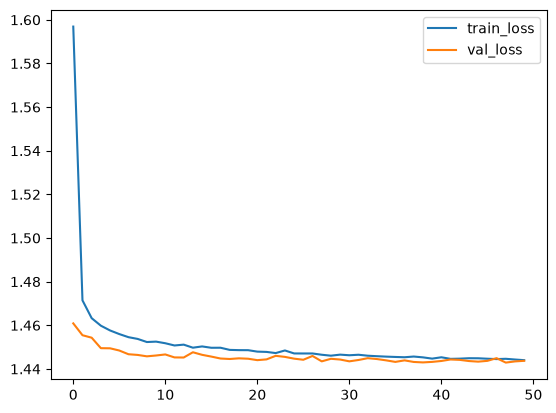

In [14]:
_ = log.plot()

Looking at the above, validation loss is seeming to fluctuate more towards the end of the training run, but it is not evident enough to say that the model is definitiely overfitting, especially since the overall trend of calidation loss is that it decreases along with training loss. To evaluate the model better, I will assess its prediction ability on the unseen test data.

Before evaluation, we need to obtain survival estimates for the test set. Then we can plot the estimates for the first 5 patients.

In [15]:
surv = model.interpolate(10).predict_surv_df(X_test)

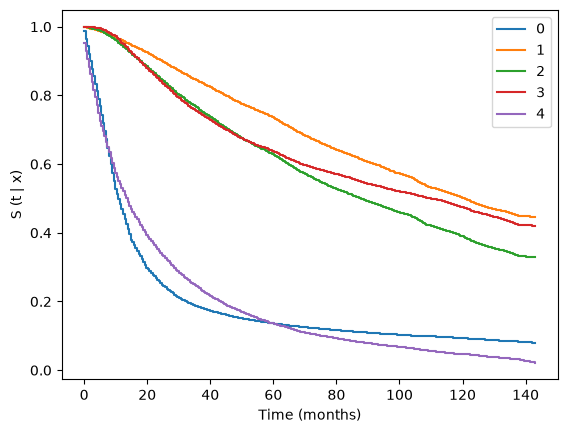

In [20]:
import matplotlib.pyplot as plt

surv.iloc[:, :5].plot(drawstyle='steps-post')
plt.ylabel('S (t | x)')
_ = plt.xlabel('Time (months)')

In [17]:
ev = EvalSurv(surv, durations_test, events_test, censor_surv='km')

In [18]:
ev.concordance_td('antolini')

0.8055371573562081

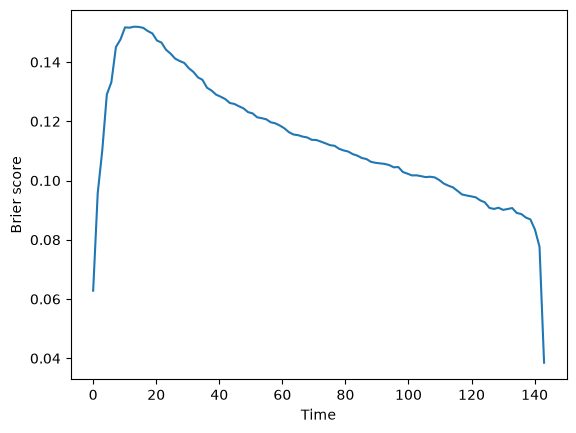

In [19]:
time_grid = np.linspace(durations_test.min(), durations_test.max(), 100)
ev.brier_score(time_grid).plot()
plt.ylabel('Brier score')
_ = plt.xlabel('Time')